<a href="https://colab.research.google.com/github/haojue23/HaojueHe-DataScience-GenAI-Submissions/blob/main/titanic_eda_seminar2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA): Titanic Passenger Data

This notebook applies the EDA workflow from session 2.05 to the Titanic dataset, which records 891 passengers. The variable of interest is **`Survived`** (1 = survived, 0 = died). The aim is to describe the structure of the data and identify which passenger characteristics are associated with survival.

We start by importing the libraries and uploading the data:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Upload the file when running in Google Colab; skipped when run locally
try:
    from google.colab import files
    upload = files.upload()
except ImportError:
    pass

We can now import the data into pandas:

In [ ]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


We can find the number of rows and columns with `.shape`:

In [ ]:
titanic.shape

(891, 12)

The data have 891 rows (passengers) and 12 columns (variables). The `info` function gives the type and the number of non-null entries for each column:

In [ ]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


The variables are of three types:

- **Strings (object):** `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`.
- **Integers:** `PassengerId`, `Survived`, `Pclass`, `SibSp`, `Parch`.
- **Floats:** `Age`, `Fare`.

Although `Survived` and `Pclass` are stored as integers, they are really **categorical** variables. `Survived` is binary, and `Pclass` is an ordered category (1 = Upper, 2 = Middle, 3 = Lower). Some columns have fewer than 891 non-null entries, so we check for missing data:

In [ ]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

As a percentage of each column:

In [ ]:
# Percent of data which is not available
titanic.isnull().sum() / len(titanic) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

Three columns have missing values:

- `Cabin` is about 77% missing. This is too much to be useful as it stands, so it is a candidate for dropping.
- `Age` is about 20% missing.
- `Embarked` has only 2 missing values (0.2%).

Next, we check for duplicate rows:

In [ ]:
titanic.duplicated().value_counts()

False    891
Name: count, dtype: int64

There are no duplicates: all 891 records return `False`. Pandas also gives summary statistics for the numeric columns:

In [ ]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Several points stand out:

- **Survived:** the mean is 0.38. Because the variable is coded 0/1, the mean is the proportion who survived, so **38% of passengers in the data survived**.
- **Pclass:** the median is 3, so more than half of the passengers travelled in third class.
- **Age:** ages range from under 1 to 80, with a mean of 29.7 and a median of 28.
- **SibSp and Parch:** both medians are 0, so most passengers travelled without siblings, spouses, parents or children.
- **Fare:** the mean (£32.20) is more than double the median (£14.45), and the maximum is £512. This indicates a strongly right-skewed distribution.

Passing `include='object'` describes the text columns:

In [ ]:
titanic.describe(include='object')

/tmp/ipykernel_228/26763510.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  titanic.describe(include='object')


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


There are more men than women (577 of 891 passengers are male). Southampton (`S`) was by far the most common port of embarkation. Every `Name` is unique, which means names carry no shared information across passengers.

### Visualising the Data

#### The target variable

We start with the outcome itself:

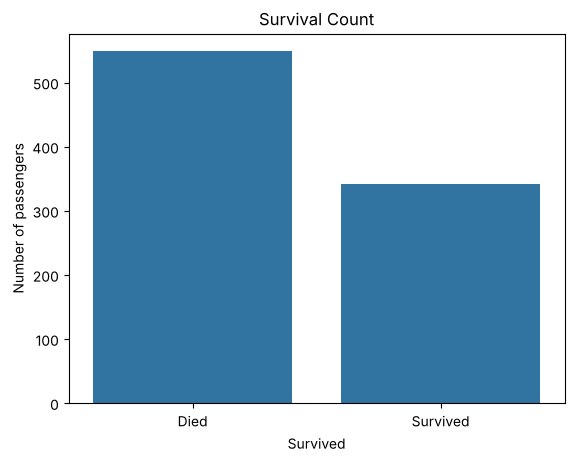

Survived
0    549
1    342
Name: count, dtype: int64

In [ ]:
sns.countplot(x='Survived', data=titanic)
plt.xticks([0, 1], ['Died', 'Survived'])
plt.ylabel('Number of passengers')
plt.title('Survival Count')
plt.show()

titanic['Survived'].value_counts()

549 passengers died and 342 survived. The classes are therefore somewhat imbalanced, at about 62% and 38%.

#### Survival by sex and class

Because `Survived` is coded 0/1, a bar chart of its **mean** for each group shows the **survival rate** of that group. Seaborn's `barplot` calculates the mean automatically. The black line on each bar is a 95% confidence interval.

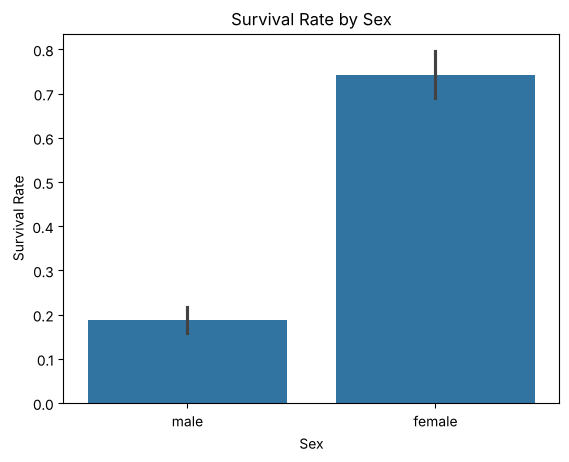

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [ ]:
sns.barplot(x='Sex', y='Survived', data=titanic)
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Sex')
plt.show()

titanic.groupby('Sex')['Survived'].mean()

Sex has a very large effect. **74% of women survived, compared with only 19% of men.** This is consistent with the "women and children first" evacuation rule.

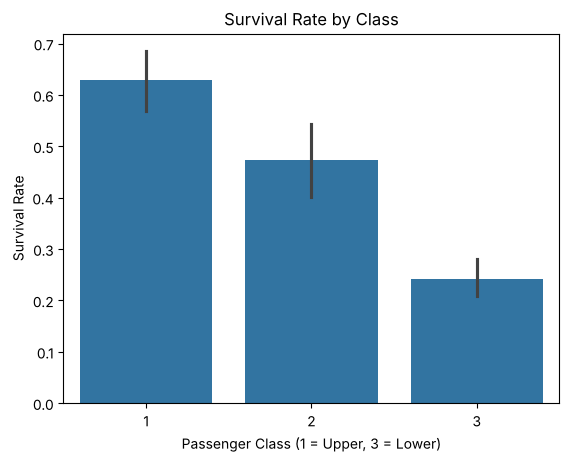

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [ ]:
sns.barplot(x='Pclass', y='Survived', data=titanic)
plt.xlabel('Passenger Class (1 = Upper, 3 = Lower)')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Class')
plt.show()

titanic.groupby('Pclass')['Survived'].mean()

There is a clear class gradient. **63% of first-class passengers survived, compared with 47% in second class and 24% in third class.** The `hue` argument lets us combine sex and class in a single chart:

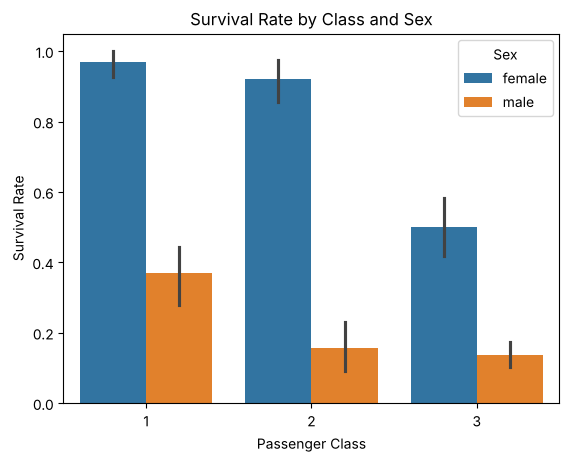

Sex,female,male
Pclass,,
1,0.97,0.37
2,0.92,0.16
3,0.50,0.14


In [ ]:
sns.barplot(x='Pclass', y='Survived', hue='Sex', hue_order=['female', 'male'], data=titanic)
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Class and Sex')
plt.show()

pd.crosstab(titanic['Pclass'], titanic['Sex'], values=titanic['Survived'], aggfunc='mean').round(2)

Combining the two variables gives a more detailed picture:

- Nearly all first- and second-class women survived (97% and 92%), but only **half of third-class women** did.
- For men, the main gap is between first class (37%) and the other two classes (16% and 14%).

The two effects therefore interact. The effect of class depends on sex.

#### Survival by port of embarkation

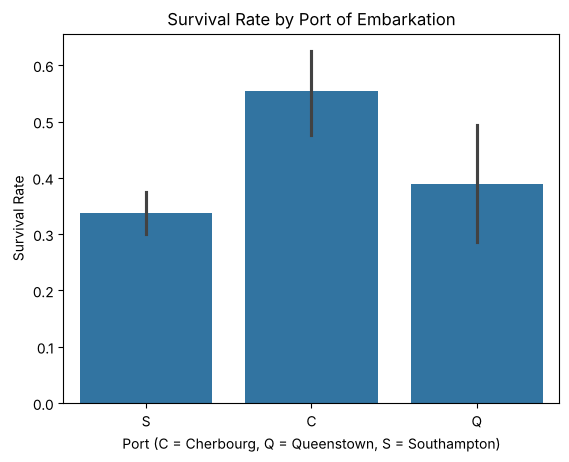

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


In [ ]:
sns.barplot(x='Embarked', y='Survived', data=titanic)
plt.xlabel('Port (C = Cherbourg, Q = Queenstown, S = Southampton)')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Port of Embarkation')
plt.show()

pd.crosstab(titanic['Embarked'], titanic['Pclass'], normalize='index').round(2)

Passengers who boarded at Cherbourg survived at a higher rate (55%) than those from Southampton (34%). The crosstab shows why: about half of the Cherbourg passengers travelled first class, compared with 20% of those from Southampton. The port effect is therefore largely a **class effect** in disguise. This illustrates the importance of examining variables together, not only one at a time.

#### Distributions of Age and Fare

Next, we check how close the numeric variables are to a normal distribution, using histograms:

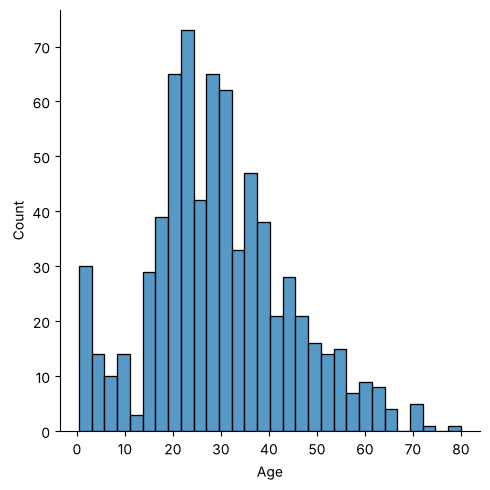

In [ ]:
ax = sns.displot(titanic['Age'].dropna(), bins=30)

Age is roughly bell-shaped, with a slight right skew. It has a peak in the 20s and a smaller group of young children aged 0–5. For practical purposes, it is close enough to normal.

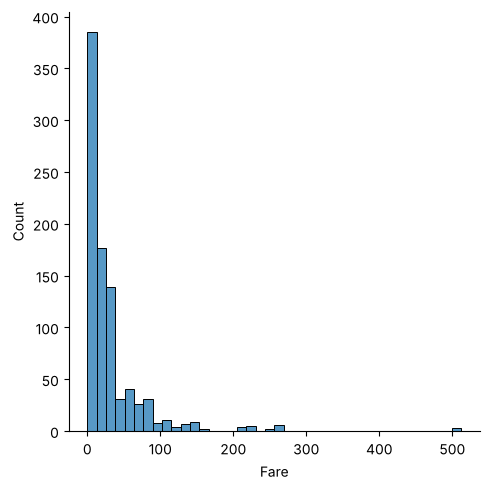

In [ ]:
ax = sns.displot(titanic['Fare'], bins=40)

Fare is very far from normal. Most passengers paid under £50, but a long tail extends to £512. This matches the gap between the mean and the median that we found earlier. A log transformation makes the distribution much more symmetric:

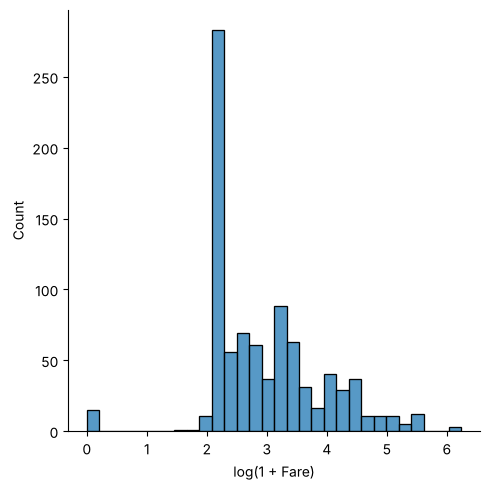

In [ ]:
ax = sns.displot(np.log1p(titanic['Fare']), bins=30)
plt.xlabel('log(1 + Fare)')
plt.show()

#### Age, Fare and survival

Splitting the age histogram by outcome shows whether age is related to survival:

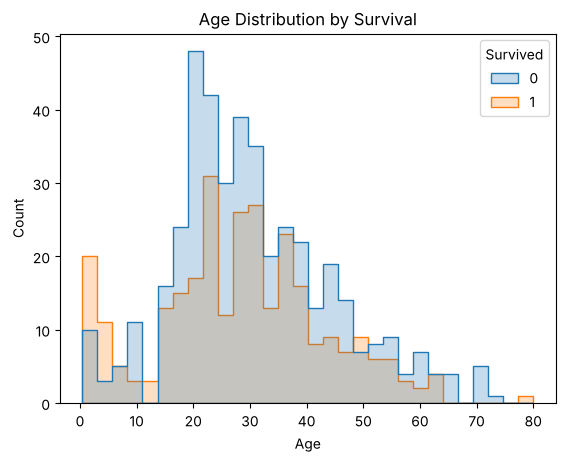

In [ ]:
sns.histplot(data=titanic, x='Age', hue='Survived', bins=30, multiple='layer', element='step')
plt.title('Age Distribution by Survival')
plt.show()

The two distributions largely overlap. The clear exception is young children, among whom survivors outnumber those who died. Age therefore seems to matter mostly at the young end, not in a simple linear way.

Grouping ages into bands makes this pattern easier to see:

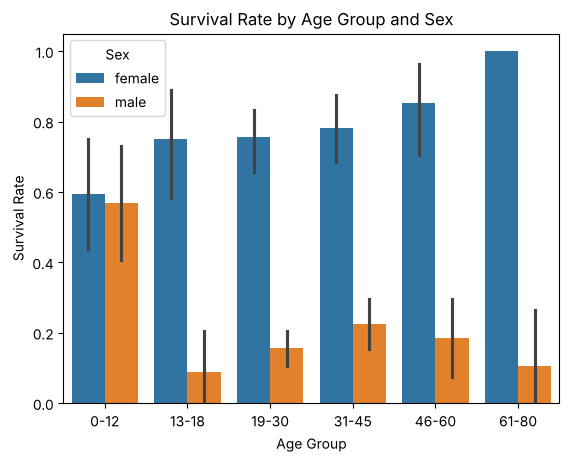

In [ ]:
titanic['AgeGroup'] = pd.cut(titanic['Age'], bins=[0, 12, 18, 30, 45, 60, 80],
                             labels=['0-12', '13-18', '19-30', '31-45', '46-60', '61-80'])
sns.barplot(x='AgeGroup', y='Survived', hue='Sex', hue_order=['female', 'male'], data=titanic)
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Age Group and Sex')
plt.show()

Boys and girls aged 12 or under survived at similar rates (about 57–59%). From the teenage years onwards, male survival falls sharply to roughly 10–20%, while female survival stays high. This is the "children first" part of the rule. It applied to boys only until about age 12.

A scatter plot of Age against Fare, coloured by outcome:

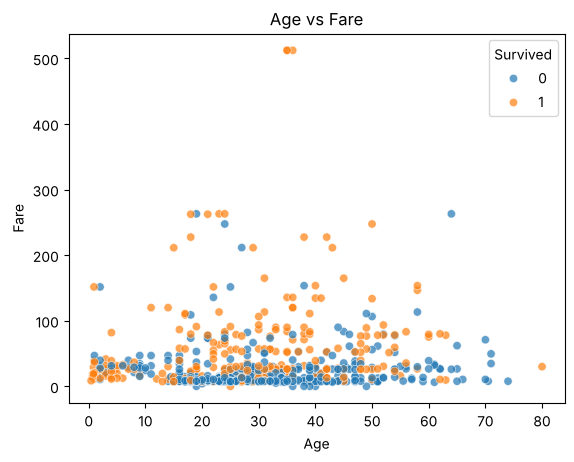

In [ ]:
sns.scatterplot(data=titanic, x='Age', y='Fare', hue='Survived', alpha=0.7)
plt.title('Age vs Fare')
plt.show()

There is no strong relationship between age and fare. However, survivors (orange points) are more common among higher fares, which reflects the class effect seen earlier. Most third-class passengers are clustered near the bottom of the chart.

#### Family size

`SibSp` and `Parch` can be combined into a single family-size variable, which counts the passenger plus their relatives on board:

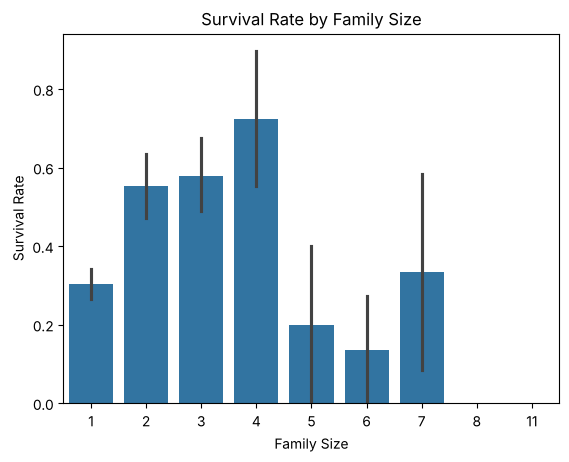

In [ ]:
titanic['FamilySize'] = titanic['SibSp'] + titanic['Parch'] + 1
sns.barplot(x='FamilySize', y='Survived', data=titanic)
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Family Size')
plt.show()

The relationship is not linear. Passengers travelling **alone** survived at a rate of about 30%. **Small families of 2–4** did best, at roughly 55–72%. **Large families of 5 or more** did poorly. Very large families have few observations, so their confidence intervals are wide.

#### Pairplot and correlations

As in the session notebook, `pairplot()` shows all pairs of numeric variables. Here the points are coloured by survival:

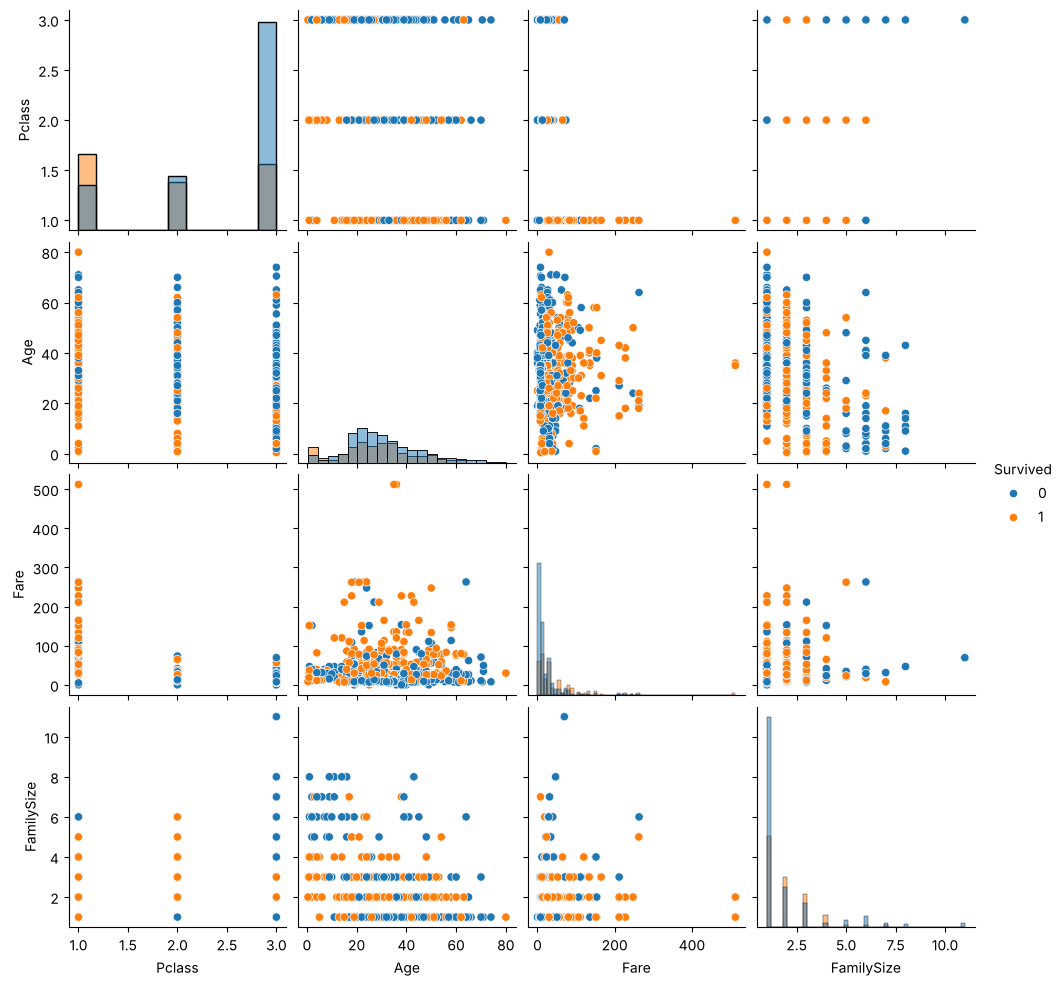

In [ ]:
sns.pairplot(data=titanic[['Survived', 'Pclass', 'Age', 'Fare', 'FamilySize']], hue='Survived', diag_kind='hist')
plt.show()

A correlation heatmap summarises the same relationships as numbers. We first convert `Sex` to a 0/1 variable so that it can be included:

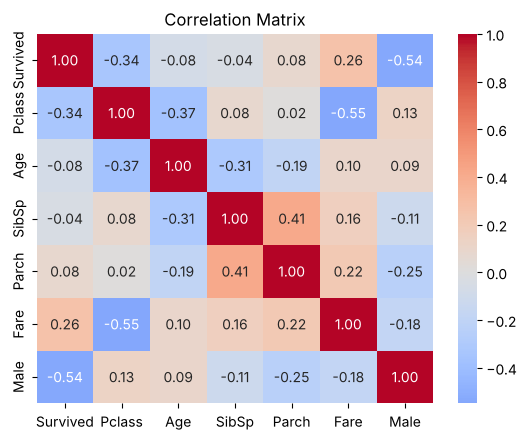

In [ ]:
corr_data = titanic[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
corr_data['Male'] = (titanic['Sex'] == 'male').astype(int)

sns.heatmap(corr_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

- **Male (−0.54)** has the strongest correlation with survival. **Pclass (−0.34)** comes next: lower-class passengers were less likely to survive. **Fare (+0.26)** is positively correlated with survival.
- **Pclass and Fare** are strongly correlated with each other (−0.55). Both measure the same underlying thing, namely wealth and status.
- **Age** is barely correlated with survival (−0.08). This is consistent with the histogram, because its effect is concentrated among children and is not linear.
- **SibSp and Parch** are positively correlated with each other (0.41), which is why combining them into family size makes sense.

### Removing Variables

Finally, as in the session notebook, we drop variables that will not help further analysis:

- `PassengerId` is just a row number.
- `Name` is unique for every passenger.
- `Ticket` is an identifier with 681 different values.
- `Cabin` is about 77% missing.

In [ ]:
titanic = titanic.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
titanic.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,AgeGroup,FamilySize
0,0,3,male,22.0,1,0,7.2500,S,19-30,2
1,1,1,female,38.0,1,0,71.2833,C,31-45,2
2,1,3,female,26.0,0,0,7.9250,S,19-30,1
3,1,1,female,35.0,1,0,53.1000,S,31-45,2
4,0,3,male,35.0,0,0,8.0500,S,31-45,1


### Summary

1. **38%** of passengers in the data survived.
2. **Sex** is the strongest factor: 74% of women survived, against 19% of men.
3. **Class** also matters a great deal: 63% survived in first class, against 24% in third. The two factors interact, and third-class women fared much worse than other women.
4. **Age** matters mainly for **young children**, not as a straight-line effect.
5. **Port** looks important, but this is mostly because of class composition: many Cherbourg passengers travelled first class.
6. **Fare** is heavily skewed and closely linked to class.
7. **Family size** has a non-linear effect: small families did best, and those alone or in large families did worst.

These patterns suggest that sex, class, age group and family size are the most promising inputs for a model that predicts survival.